First five rows:
   radius1  texture1  perimeter1   area1  smoothness1  compactness1  \
0    17.99     10.38      122.80  1001.0      0.11840       0.27760   
1    20.57     17.77      132.90  1326.0      0.08474       0.07864   
2    19.69     21.25      130.00  1203.0      0.10960       0.15990   
3    11.42     20.38       77.58   386.1      0.14250       0.28390   
4    20.29     14.34      135.10  1297.0      0.10030       0.13280   

   concavity1  concave_points1  symmetry1  fractal_dimension1  ...  radius3  \
0      0.3001          0.14710     0.2419             0.07871  ...    25.38   
1      0.0869          0.07017     0.1812             0.05667  ...    24.99   
2      0.1974          0.12790     0.2069             0.05999  ...    23.57   
3      0.2414          0.10520     0.2597             0.09744  ...    14.91   
4      0.1980          0.10430     0.1809             0.05883  ...    22.54   

   texture3  perimeter3   area3  smoothness3  compactness3  concavity3  \
0     1

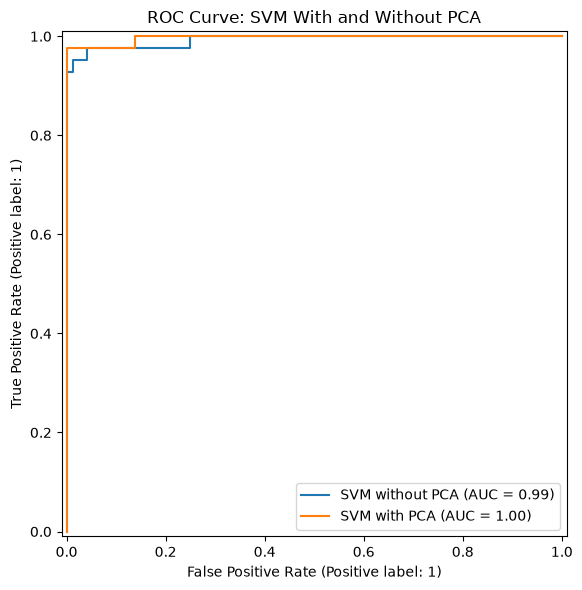


FINAL MODEL COMPARISON
          Model                          Best Parameters  Accuracy  F1-score  ROC-AUC
SVM without PCA     {'svc__C': 10, 'svc__kernel': 'rbf'}  0.973684  0.962963 0.992725
   SVM with PCA {'svc__C': 0.1, 'svc__kernel': 'linear'}  0.982456  0.975610 0.996693

Best model by F1-score: SVM with PCA
Best F1-score: 0.9756


In [14]:
# ============================================================
# BREAST CANCER CLASSIFICATION - COMPLETE ML PIPELINE
# Dataset: UCI Breast Cancer Wisconsin (Diagnostic), ID 17
# Models: SVM without PCA and SVM with PCA
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.pipeline import make_pipeline

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)


# ------------------------------------------------------------
# 1. LOAD THE DATASET
# ------------------------------------------------------------

cancer_data = fetch_ucirepo(id=17)

X = cancer_data.data.features.copy()
y = cancer_data.data.targets.iloc[:, 0].copy()

print("First five rows:")
print(X.head())

print("\nDataset shape:", X.shape)
print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())


# ------------------------------------------------------------
# 2. EXPLORATORY DATA ANALYSIS (EDA)
# ------------------------------------------------------------

print("\nDataset information:")
print(X.info())

print("\nStatistical summary:")
print(X.describe())

print("\nMissing values:")
print(X.isnull().sum().sum())

print("\nDuplicate rows:", X.duplicated().sum())

# Target: B = Benign, M = Malignant
y = y.map({"B": 0, "M": 1})

if y.isnull().any():
    raise ValueError("Unexpected target labels found.")

print("\nClass distribution (0 = Benign, 1 = Malignant):")
print(y.value_counts())


# ------------------------------------------------------------
# 3. PREPROCESSING AND FEATURE SELECTION
# ------------------------------------------------------------

# Remove columns that are completely missing, if any.
X = X.dropna(axis=1, how="all")

# Split the dataset into training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# StandardScaler standardizes numerical features.
# PCA retains 95% of the variance.

num_colmn = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

cat_colmn = X.select_dtypes(
    exclude=["int64", "float64"]
).columns.tolist()

num_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

pipeline_2 = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(sparse_output=False)
)

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_colmn),
    ("cat", pipeline_2, cat_colmn)
])


# ------------------------------------------------------------
# 4. DEFINE SVM PIPELINES
# ------------------------------------------------------------

models = {
    "SVM without PCA": make_pipeline(
        preprocessor,
        SVC()
    ),

    "SVM with PCA": make_pipeline(
        preprocessor,
        PCA(n_components=0.95),
        SVC()
    )
}


# ------------------------------------------------------------
# 5. HYPERPARAMETER TUNING AND MODEL EVALUATION
# ------------------------------------------------------------

param_grid = {
    "svc__C": [0.1, 1, 10],
    "svc__kernel": ["linear", "rbf"]
}

results = []
fig, ax = plt.subplots(figsize=(8, 6))

for name, pipeline in models.items():

    # Tune SVM parameters using 5-fold cross-validation.
    grid = GridSearchCV(
        pipeline,
        param_grid,
        cv=5,
        scoring="f1",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_

    # Predict on unseen test data.
    y_pred = best_model.predict(X_test)

    # Continuous decision scores are used for ROC-AUC.
    y_score = best_model.decision_function(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_score)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    results.append({
        "Model": name,
        "Best Parameters": grid.best_params_,
        "Accuracy": accuracy,
        "F1-score": f1,
        "ROC-AUC": auc
    })

    print("\n" + "=" * 50)
    print("MODEL:", name)
    print("=" * 50)

    print("Best parameters:", grid.best_params_)
    print(f"Accuracy : {accuracy:.4f}")
    print(f"F1-score : {f1:.4f}")
    print(f"ROC-AUC  : {auc:.4f}")

    print("\nConfusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Benign", "Malignant"],
        zero_division=0
    ))

    # Plot ROC curve using decision scores.
    RocCurveDisplay.from_predictions(
        y_test, y_score,
        name=name,
        ax=ax
    )

    # Display the number of PCA components retained.
    if "pca" in best_model.named_steps:
        print(
            "PCA components retained:",
            best_model.named_steps["pca"].n_components_
        )


# ------------------------------------------------------------
# 6. COMPARE BOTH MODELS
# ------------------------------------------------------------

plt.title("ROC Curve: SVM With and Without PCA")
plt.tight_layout()
plt.show()

results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")
print(results_df.to_string(index=False))

best_result = results_df.loc[
    results_df["F1-score"].idxmax()
]

print("\nBest model by F1-score:", best_result["Model"])
print("Best F1-score:", round(best_result["F1-score"], 4))